In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\chuan\Desktop\Ironhack\Week 5\Day 1\amz_uk_price_prediction_dataset.csv")

display(df)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [6]:
# Display all columns 
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
# Display the first few rows of the dataset
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
# Retrieving the number of rows and columns in the dataframe
df.shape

(2443651, 9)

In [8]:
# Displaying the data types of each column in the dataframe
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [20]:
# Check for missing values
display(df.isnull().sum())

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [25]:
# EDA Analysis
# Part 1. Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
# 1. Frequency Tables:
# 1.1 Generate a frequency table for the product category.
frequency = df['category'].value_counts()

# 1.2 Which are the top 5 most listed product categories?
Top_5_categories = display(frequency.head(5))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

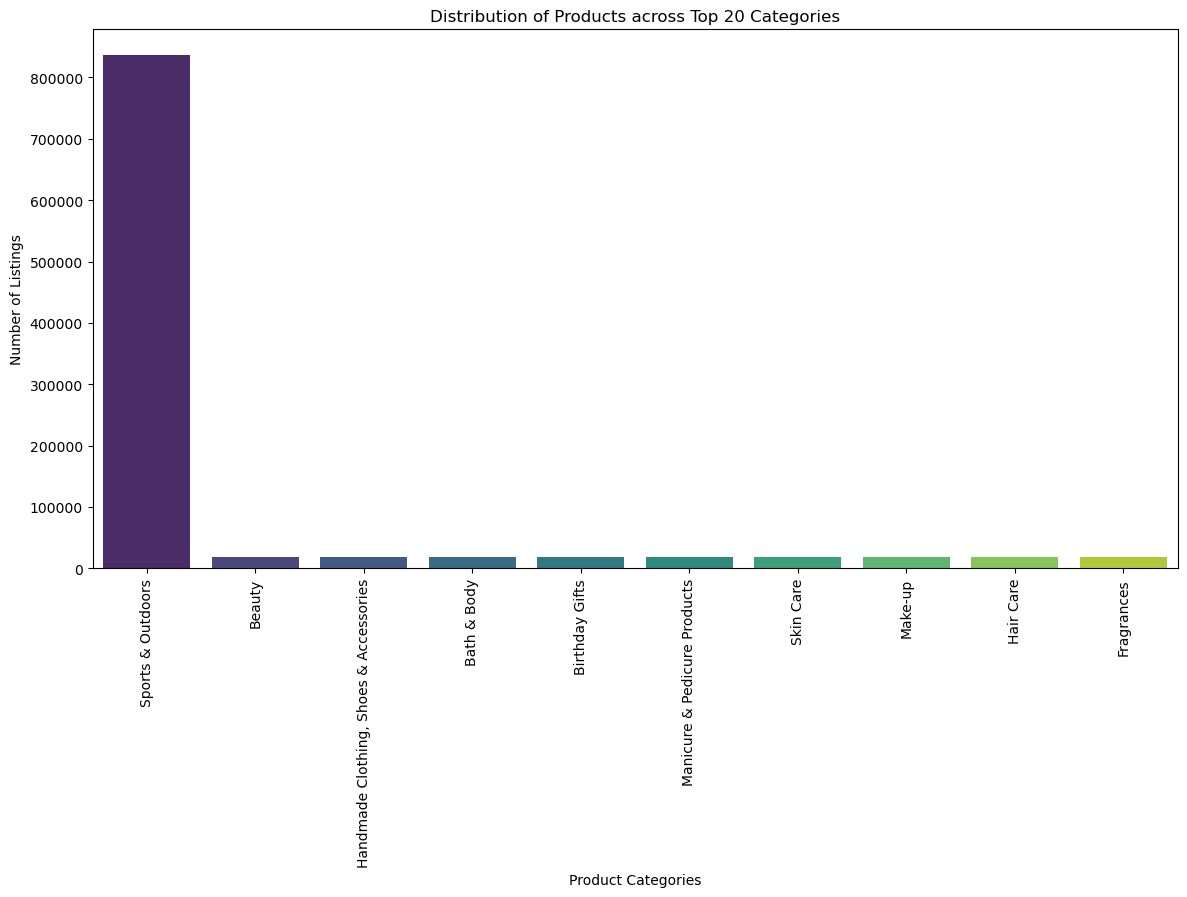

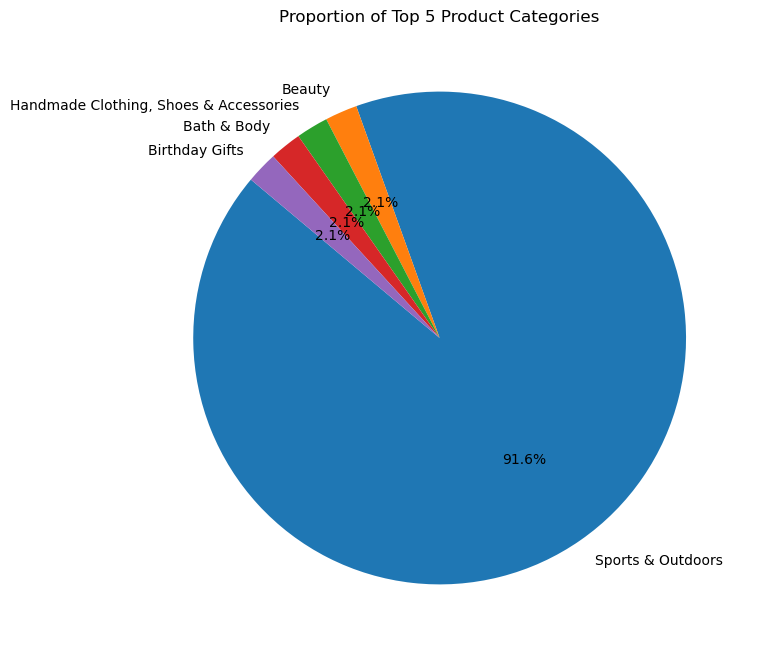

In [37]:
# 2. Visualizations:
import matplotlib.pyplot as plt
import seaborn as sns

# 2.1 Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
top_10_categories = frequency.head(10)
plt.figure(figsize=(14, 7))
sns.barplot(x=top_10_categories.index, y=top_10_categories.values, palette='viridis')
plt.xticks(rotation=90)
plt.xlabel('Product Categories')
plt.ylabel('Number of Listings')
plt.title('Distribution of Products across Top 20 Categories')
plt.show()

# 2.2 For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
top_5_categories = frequency.head(5)
plt.figure(figsize=(8, 8))
top_5_categories.plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Top 5 Product Categories')
plt.ylabel('')
plt.show()

In [53]:
# Part 2: Delving into Product Pricing. Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
# 1. Measures of Centrality:
# 1.1 Calculate the mean, median, and mode for the price of products.
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]
display(mean_price, median_price, mode_price)

# 1.2 What's the average price point of products listed? How does this compare with the most common price point (mode)?
# average price = 89, which is much greater than the most common price = 9.99 


89.24380943923663

19.09

9.99

In [56]:
# 2. Measures of Dispersion:
# 2.1 Determine the variance, standard deviation, range, and interquartile range for product price.
var_price = df['price'].var()
std_price = df['price'].std()
range_price = df['price'].max() - df['price'].min()
iqr_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)
display(var_price, std_price, range_price, iqr_price)

# 2.2 How varied are the product prices? Are there any indicators of a significant spread in prices?
# --> Product prices show significant variability.
# --> There are wide range between the highest and lowest priced product 

119445.48532256528

345.60886175352226

100000.0

36.0

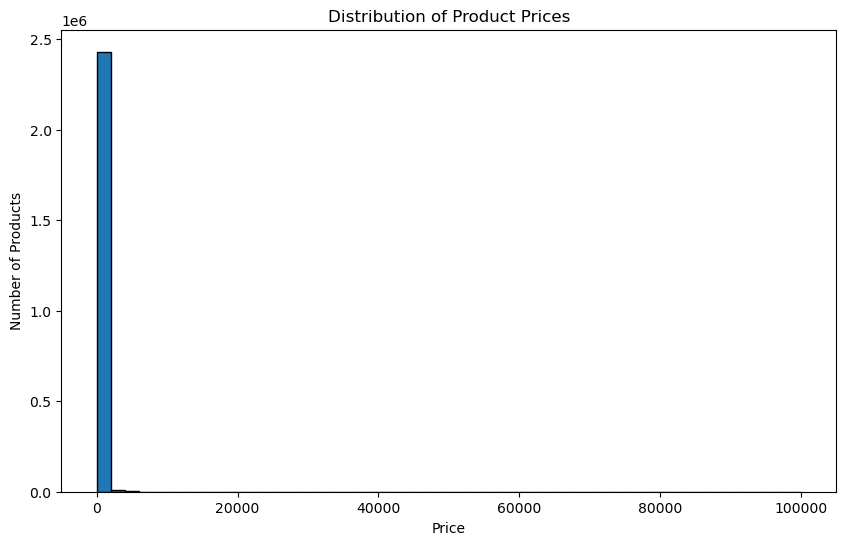

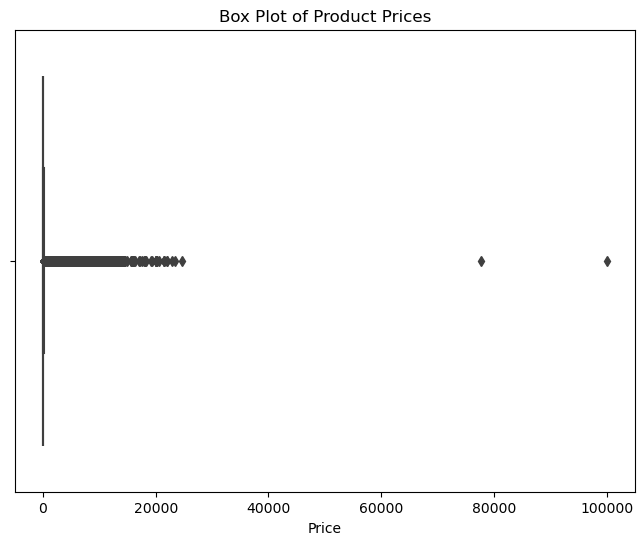

In [62]:
# 3. Visualizations:
# 3.1 Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=50, edgecolor='black')
plt.xlabel('Price')
plt.ylabel('Number of Products')
plt.title('Distribution of Product Prices')
plt.show()
# --> Conclusion: Yes. 

# 3.2 Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['price'])
plt.xlabel('Price')
plt.title('Box Plot of Product Prices')
plt.show()
# --> Conlusion: Yes, there is product priced significantly higher than the rest. 

In [66]:
# Part 3: Unpacking Product Ratings. Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?
# 1. Measures of Centrality:
# 1.1 Calculate the mean, median, and mode for the rating of products.
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]
display(mean_stars, median_stars, mode_stars)

# 1.2 How do customers generally rate products? Is there a common trend?
# --> Customers rate products by giving stars. 


2.152836472966065

0.0

0.0

5.0

0.0

In [75]:
# 2. Measures of Dispersion:
# 2.1 Determine the variance, standard deviation, and interquartile range for product rating.
var_stars = df['stars'].var()
std_stars = df['stars'].std()
range_stars = df['stars'].max() - df['stars'].min()
iqr_stars = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)
display(var_stars, std_stars, range_stars, iqr_stars)

# 2.2 Are the ratings consistent, or is there a wide variation in customer feedback?
# --> The ratings are not consistant, there is wide variation in customer feedback. 

4.81743402976196

2.1948653785054697

5.0

4.4

In [68]:
# 3. Shape of the Distribution:
# 3.1 Calculate the skewness and kurtosis for the rating column.
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurt()
display(skewness_stars, kurtosis_stars)

# 3.2 Are the ratings normally distributed, or do they lean towards higher or lower values?
# --> not very normal, it goes to the lower/negatuve values. 

0.08120735761080985

-1.9260061280432985

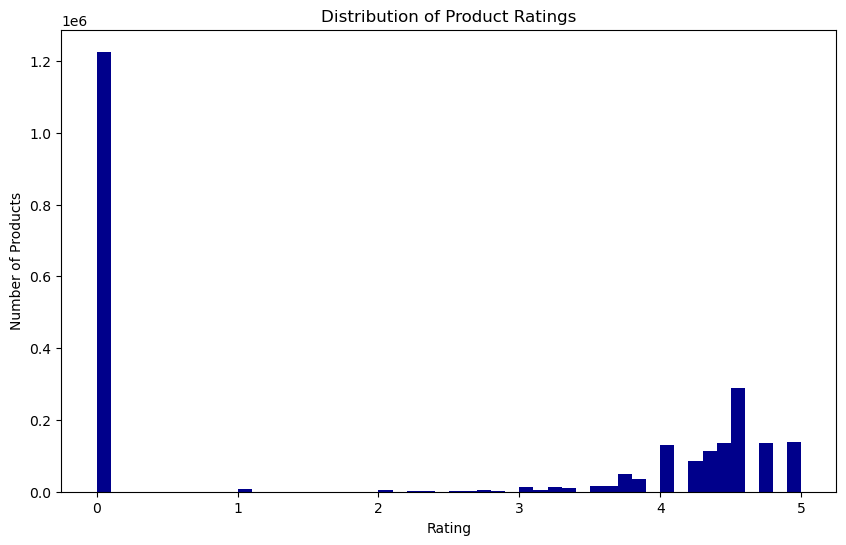

In [76]:
# 4. Visualizations:
# 4.1 Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
plt.figure(figsize=(10, 6))
plt.hist(df['stars'], bins=50, color='darkblue')
plt.xlabel('Rating')
plt.ylabel('Number of Products')
plt.title('Distribution of Product Ratings')
plt.show()